# Grammar Scoring Engine for Spoken English — SHL Hiring Assessment 2026

**Task:** given a 45–60 s audio clip, predict the MOS grammar score (0–5).
**Metric:** RMSE (leaderboard) and Pearson correlation.

## Report (summary)

**Approach in one line:** turn each clip into a few strong, interpretable signals — *what was said* (transcript-based grammar features + an LLM rubric judge) and *how it was said* (speech-model embeddings) — then combine them with simple regressors (Ridge + LightGBM), validated with 5-fold cross-validation.

| Stage | What | Why |
|---|---|---|
| 1. Preprocessing | Resample all audio to 16 kHz mono (librosa). | Whisper and WavLM both expect 16 kHz. |
| 2. Transcription | `transcribe.py`: Whisper large-v3, no VAD, no context conditioning. | Keep hesitations / errors; they are the signal. |
| 3. Text features | 8 fluency features + 4 CoLA grammaticality features. | Cheap, interpretable. |
| 4. LLM judge | One rubric score (1–5) per transcript (`llm_score.py`, same prompt for every judge). | Directly applies the SHL rubric. |
| 5. Audio features | `audio_embed.py`: frozen WavLM-large, mean+std pooled, best layers chosen by CV → Ridge → one out-of-fold feature. | Audio carries errors the transcript hides (ASR "cleans up" grammar). |
| 6. Fine-tuned audio | `finetune.py`: WavLM fine-tuned to regress the score (30 s crops, 10-fold) → out-of-fold feature. | Learns task-specific acoustic cues. |
| 7. Final model | Ridge + LightGBM on the stacked features, averaged, clipped to [0, 5]. | 769 samples → small, regularised models. |

**Results (5-fold CV on train, see Section 6):** RMSE ≈ 0.46, Pearson r ≈ 0.93.

The heavy steps (Whisper, LLM scoring, WavLM extraction / fine-tuning) are separate scripts whose outputs are cached as CSV/NPZ files; this notebook loads those caches so it runs in minutes. Run order is in `README.md`.


In [1]:
import re
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import lightgbm as lgb
from pathlib import Path
from scipy.stats import pearsonr
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA = Path('data/Dataset_Final')
SEED = 0
kf = KFold(5, shuffle=True, random_state=SEED)
sns.set_theme(style='whitegrid')

def rmse(p, y): return float(np.sqrt(((p - y) ** 2).mean()))
def report(name, p, y):
    p = np.clip(p, 0, 5)
    return {'model': name, 'RMSE': round(rmse(p, y), 3), 'Pearson r': round(pearsonr(p, y)[0], 3)}

## 1. Data

train 769  test 216
NB: train/ and test/ reuse the same file names for different recordings, so every join below uses (split, filename).


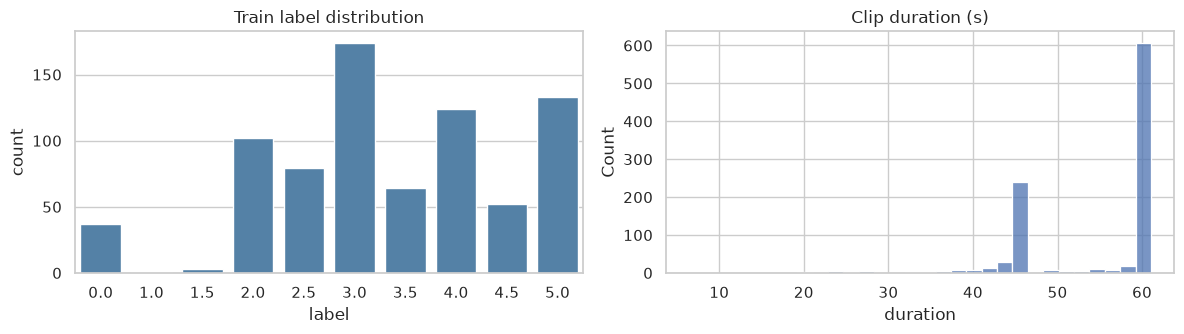

In [2]:
train = pd.read_csv(DATA / 'train.csv')
test = pd.read_csv(DATA / 'test.csv')[['filename']]   # test.csv labels are placeholders
y = train.label.values
print(f'train {len(train)}  test {len(test)}')
print('NB: train/ and test/ reuse the same file names for different recordings, so every join below uses (split, filename).')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
sns.countplot(x=train.label, ax=ax[0], color='steelblue'); ax[0].set_title('Train label distribution')
t = pd.read_csv('transcripts.csv')
sns.histplot(t.duration, bins=30, ax=ax[1]); ax[1].set_title('Clip duration (s)')
plt.tight_layout(); plt.show()

Labels are on a 0–5 half-point scale, mostly 2–5. The **37 clips scored 0** sit outside the 1–5 rubric: listening/reading them shows silent, off-topic or unusable recordings (e.g. Whisper hallucinating *"Thanks for watching!"* on near-silence). The `no_speech_prob` and audio features let the model recognise them.

## 2. Transcripts (Whisper large-v3)

In [3]:
def split_join(df, split, other, cols):
    o = other[other.split == split][['filename', *cols]]
    out = df[['filename']].merge(o, on='filename', how='left')
    assert len(out) == len(df), 'join changed row count'
    return out

tr = train.merge(t[t.split == 'train'], on='filename')
te = test.merge(t[t.split == 'test'], on='filename')
tr.text, te.text = tr.text.fillna(''), te.text.fillna('')
tr[['filename', 'label', 'text']].head(5)

,filename,label,text
0,audio_192.wav,3.0,"The playground is very, very beautiful and fun..."
1,audio_436.wav,3.0,The scene of a school playground. Our playgrou...
2,audio_447.wav,3.5,my favorite place to visit is the beach I love...
3,audio_126.wav,2.0,Once upon a time we with five friends went on ...
4,audio_61.wav,2.0,"Well, when I was a child, I remember I went to..."
